<a href="https://colab.research.google.com/github/NoeliaFerrero/Comi-96160-Data-Science-II-Machine-Learning-para-la-Ciencia-de-Datos-Diplomaturas/blob/main/Semana%2015%20Validacion%20y%20Problemas%20en%20ML/Masterclass_Data_Science.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Science: del problema a la decisión
## Notebook de refuerzo — detección de fraude

**Objetivo:** practicar el criterio para elegir un enfoque y evaluar un modelo según el problema de negocio.

> Caso ficticio y datos sintéticos. No representan operaciones bancarias reales.

### Antes de ejecutar
1. Lean la pregunta de negocio.
2. Anticipen qué métrica sería importante y por qué.
3. Ejecuten las celdas en orden.
4. No se queden con el número: interpreten qué decisión habilita.

## 1. Primero: ¿qué necesita el negocio?

Un banco quiere **detectar transacciones fraudulentas** y reducir pérdidas. Tiene capacidad limitada para revisar alertas.

- **Pregunta analítica:** ¿podemos identificar transacciones con alta probabilidad de fraude?
- **Tipo de problema:** clasificación binaria supervisada (fraude / legítima).
- **Errores relevantes:**
  - **FN (falso negativo):** fraude que el sistema deja pasar.
  - **FP (falso positivo):** operación legítima que el sistema marca como fraude.
- **Decisión operativa:** qué transacciones enviar a revisión o bloquear.

No empezamos por el algoritmo: empezamos por esta necesidad.

## 2. Generamos un dataset sintético

La clase positiva (fraude) será minoritaria. Esto permite observar por qué Accuracy puede engañar.

**Pregunta antes de ejecutar:** si el 1% de las operaciones es fraude, ¿qué Accuracy tendría un modelo que predice siempre “legítima”?

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_auc_score,
    average_precision_score, RocCurveDisplay, PrecisionRecallDisplay
)

RANDOM_STATE = 42
X_raw, y = make_classification(
    n_samples=10_000,
    n_features=8,
    n_informative=5,
    n_redundant=2,
    n_clusters_per_class=2,
    weights=[0.99, 0.01],
    class_sep=1.5,
    flip_y=0,
    random_state=RANDOM_STATE
)

columns = [f"variable_{i}" for i in range(1, 9)]
df = pd.DataFrame(X_raw, columns=columns)
df["fraude"] = y

# Variables ilustrativas adicionales (sintéticas)
rng = np.random.default_rng(RANDOM_STATE)
df["monto"] = np.round(rng.lognormal(mean=3.5, sigma=1.0, size=len(df)), 2)
df["hora"] = rng.integers(0, 24, size=len(df))
df["fraude"] = df["fraude"].astype(int)

df.head()

,variable_1,variable_2,variable_3,variable_4,variable_5,variable_6,variable_7,variable_8,fraude,monto,hora
0,1.490068,-1.072148,0.861173,-1.092426,2.313991,-1.722085,1.885147,-3.135153,0,44.91,21
1,0.998636,0.113667,3.063596,-2.244548,2.461488,2.830874,1.759259,-3.141961,0,11.70,18
2,0.130652,0.920931,2.261011,-1.637420,1.647583,2.788618,-0.093022,-1.151484,0,70.14,16
3,2.362236,-2.103974,1.027250,-2.074019,1.919280,-2.059180,1.578769,-4.908760,0,84.82,5
4,-1.753911,-0.607740,4.549421,-1.764079,3.219679,3.203390,1.092390,-1.243813,0,4.71,14


## 3. Exploramos el problema: ¿están balanceadas las clases?

La proporción de clases condiciona cómo interpretamos las métricas.

fraude
Legítima (0)    9900
Fraude (1)       100
Name: count, dtype: int64
\nProporción de fraude: 1.0 %


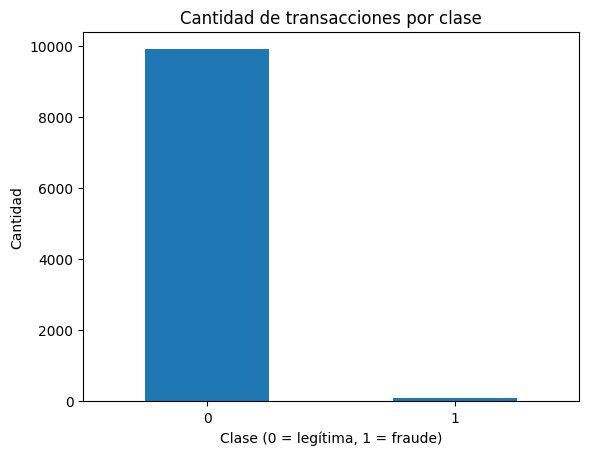

In [ ]:
conteo = df["fraude"].value_counts().sort_index()
print(conteo.rename(index={0: "Legítima (0)", 1: "Fraude (1)"}))
print("\\nProporción de fraude:", round(df["fraude"].mean() * 100, 2), "%")

conteo.plot(kind="bar")
plt.title("Cantidad de transacciones por clase")
plt.xlabel("Clase (0 = legítima, 1 = fraude)")
plt.ylabel("Cantidad")
plt.xticks(rotation=0)
plt.show()

## 4. Baseline: predecir siempre “legítima”

Un baseline ingenuo sirve como referencia. No es un modelo útil para detectar fraude, pero nos muestra el peligro de mirar solo Accuracy.

In [ ]:
y_true = df["fraude"].to_numpy()
y_baseline = np.zeros_like(y_true)

print("Accuracy baseline:", round(accuracy_score(y_true, y_baseline), 4))
print("Recall fraude baseline:", round(recall_score(y_true, y_baseline, zero_division=0), 4))
print("\\nMatriz de confusión (baseline):")
print(confusion_matrix(y_true, y_baseline))

Accuracy baseline: 0.99
Recall fraude baseline: 0.0
\nMatriz de confusión (baseline):
[[9900    0]
 [ 100    0]]


**Pausa de interpretación**

- ¿Por qué el Accuracy es alto?
- ¿Cuántos fraudes detecta?
- ¿Este modelo le sirve al banco?
- ¿Qué métrica nos revela el problema?

## 5. Separación de datos: train y test

Entrenamos con una parte y evaluamos sobre datos que el modelo no vio. Usamos `stratify` para conservar la proporción de clases.

El test se reserva para la evaluación final; no lo usamos para elegir repetidamente el modelo o el umbral.

In [ ]:
X = df.drop(columns="fraude")
y = df["fraude"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Fraude en train:", round(y_train.mean() * 100, 2), "%")
print("Fraude en test:", round(y_test.mean() * 100, 2), "%")

Train: (7500, 10) | Test: (2500, 10)
Fraude en train: 1.0 %
Fraude en test: 1.0 %


## 6. Modelo 1: Logistic Regression (baseline supervisado)

Es una alternativa sencilla para empezar. Escalamos las variables dentro de un pipeline para evitar ajustar el escalador con información del test.

Usamos `class_weight="balanced"` como una opción para atender el desbalance. **No garantiza un mejor resultado**: después hay que evaluar.

In [ ]:
log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)
)
log_reg.fit(X_train, y_train)

pred_lr = log_reg.predict(X_test)
prob_lr = log_reg.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred_lr, digits=3, zero_division=0))

              precision    recall  f1-score   support

           0      0.999     0.845     0.915      2475
           1      0.057     0.920     0.106        25

    accuracy                          0.846      2500
   macro avg      0.528     0.882     0.511      2500
weighted avg      0.990     0.846     0.907      2500



## 7. Matriz de confusión: ¿qué errores comete?

Recordatorio:
- TN: legítima correctamente identificada.
- FP: legítima marcada como fraude (falsa alarma).
- FN: fraude que no detectamos.
- TP: fraude detectado.

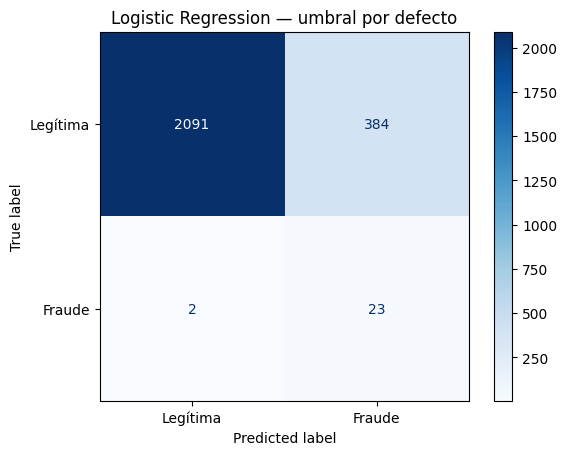

TN=2091 | FP=384 | FN=2 | TP=23


In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_lr,
    display_labels=["Legítima", "Fraude"],
    cmap="Blues",
    values_format="d"
)
plt.title("Logistic Regression — umbral por defecto")
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, pred_lr).ravel()
print(f"TN={tn} | FP={fp} | FN={fn} | TP={tp}")

## 8. Métricas: cada una responde una pregunta

| Métrica | Pregunta |
|---|---|
| Accuracy | ¿Qué proporción total acerté? |
| Precision | De las alertas, ¿cuántas eran fraude? |
| Recall | De los fraudes reales, ¿cuántos detecté? |
| F1 | ¿Cómo se equilibran Precision y Recall? |
| ROC-AUC | ¿Qué capacidad de ordenar positivos por encima de negativos tiene el modelo? |
| PR-AUC / Average Precision | ¿Cómo se comportan Precision y Recall al variar el umbral? |

**Importante:** ROC-AUC y Average Precision evalúan scores/ranking; no reemplazan la evaluación de una decisión operativa concreta.

In [ ]:
def resumen_metricas(y_real, y_pred, y_prob, nombre="Modelo"):
    return pd.Series({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision": precision_score(y_real, y_pred, zero_division=0),
        "Recall": recall_score(y_real, y_pred, zero_division=0),
        "F1": f1_score(y_real, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_real, y_prob),
        "Average Precision (PR-AUC aprox.)": average_precision_score(y_real, y_prob)
    })

res_lr = resumen_metricas(y_test, pred_lr, prob_lr, "Logistic Regression")
res_lr

,0
Modelo,Logistic Regression
Accuracy,0.8456
Precision,0.056511
Recall,0.92
F1,0.106481
ROC-AUC,0.937244
Average Precision (PR-AUC aprox.),0.464505


## 9. Modelo 2: Random Forest

Probamos otro algoritmo. No asumimos que será mejor: lo comparamos con el baseline anterior usando el mismo conjunto de test.

In [ ]:
rf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    min_samples_leaf=3,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf.fit(X_train, y_train)

pred_rf = rf.predict(X_test)
prob_rf = rf.predict_proba(X_test)[:, 1]

res_rf = resumen_metricas(y_test, pred_rf, prob_rf, "Random Forest")
comparacion = pd.DataFrame([res_lr, res_rf]).set_index("Modelo")
comparacion.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision (PR-AUC aprox.)
Modelo,,,,,,
Logistic Regression,0.846,0.057,0.92,0.106,0.937,0.465
Random Forest,0.994,0.917,0.44,0.595,0.998,0.820


## 10. Comparar curvas: ROC y Precision-Recall

Las curvas permiten observar el comportamiento al cambiar el umbral. En datasets muy desbalanceados, la curva Precision-Recall suele ayudar a entender mejor el desempeño sobre la clase positiva.

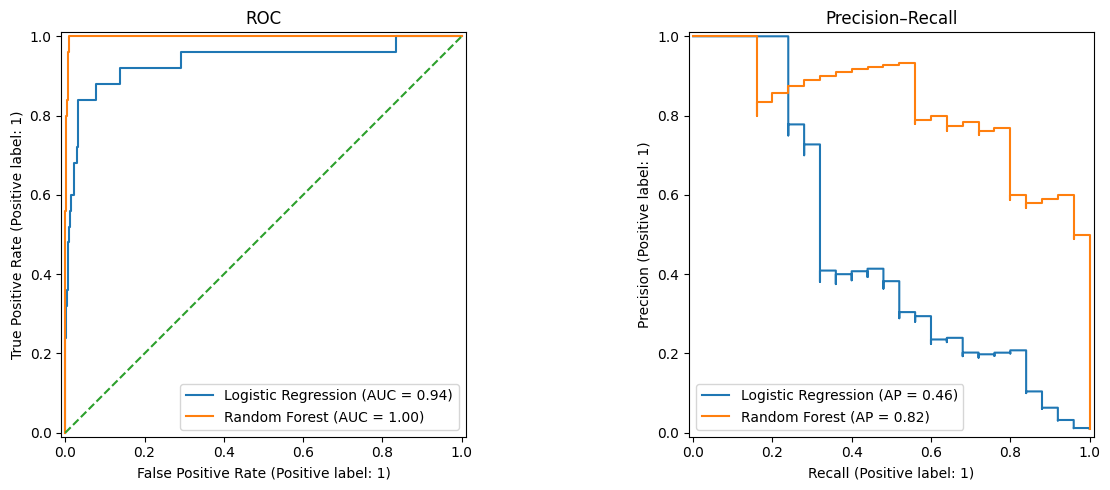

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

RocCurveDisplay.from_predictions(y_test, prob_lr, name="Logistic Regression", ax=axes[0])
RocCurveDisplay.from_predictions(y_test, prob_rf, name="Random Forest", ax=axes[0])
axes[0].plot([0, 1], [0, 1], linestyle="--", label="Azar")
axes[0].set_title("ROC")

PrecisionRecallDisplay.from_predictions(y_test, prob_lr, name="Logistic Regression", ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test, prob_rf, name="Random Forest", ax=axes[1])
axes[1].set_title("Precision–Recall")

plt.tight_layout()
plt.show()

## 11. El umbral es una decisión, no una propiedad sagrada del modelo

`predict()` suele aplicar un umbral de 0.5. Pero el negocio puede necesitar otro.

- Umbral menor: suele aumentar Recall y también las falsas alarmas.
- Umbral mayor: suele aumentar Precision y dejar pasar más positivos.

Veamos qué cambia para Random Forest.

In [ ]:
def metricas_umbral(y_real, probabilidades, umbral):
    pred = (probabilidades >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    return {
        "Umbral": umbral,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Precision": precision_score(y_real, pred, zero_division=0),
        "Recall": recall_score(y_real, pred, zero_division=0),
        "F1": f1_score(y_real, pred, zero_division=0),
        "Alertas": int(pred.sum())
    }

tabla_umbrales = pd.DataFrame([
    metricas_umbral(y_test, prob_rf, t)
    for t in [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]
])
tabla_umbrales.round(3)

,Umbral,TP,FP,FN,TN,Precision,Recall,F1,Alertas
0,0.1,25,33,0,2442,0.431,1.00,0.602,58
1,0.2,20,14,5,2461,0.588,0.80,0.678,34
2,0.3,19,6,6,2469,0.760,0.76,0.760,25
3,0.4,14,2,11,2473,0.875,0.56,0.683,16
4,0.5,11,1,14,2474,0.917,0.44,0.595,12
5,0.6,8,1,17,2474,0.889,0.32,0.471,9
6,0.7,4,0,21,2475,1.000,0.16,0.276,4
7,0.8,4,0,21,2475,1.000,0.16,0.276,4


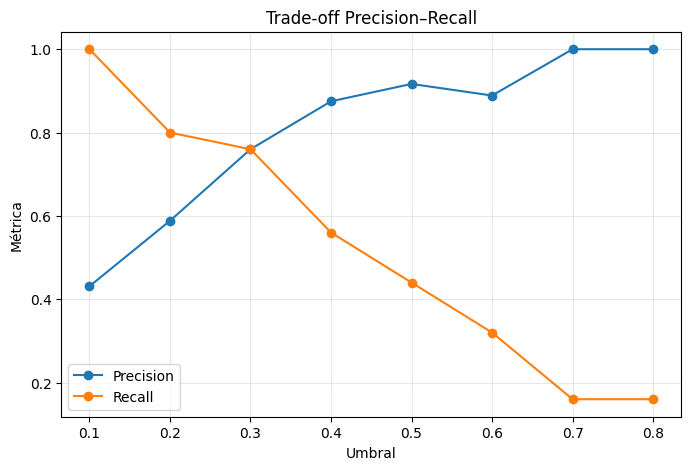

In [ ]:
# Visualizamos cómo cambian Precision y Recall
plt.figure(figsize=(8, 5))
plt.plot(tabla_umbrales["Umbral"], tabla_umbrales["Precision"], marker="o", label="Precision")
plt.plot(tabla_umbrales["Umbral"], tabla_umbrales["Recall"], marker="o", label="Recall")
plt.xlabel("Umbral")
plt.ylabel("Métrica")
plt.title("Trade-off Precision–Recall")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Discusión de negocio

Supongamos que el equipo puede investigar **como máximo 100 alertas por día** (el límite es ilustrativo).

- ¿Qué umbral genera una cantidad de alertas manejable?
- ¿Cuánto Recall conseguimos?
- ¿Cuántos fraudes quedan sin detectar?
- ¿Qué costo tiene cada falsa alarma?
- ¿Qué decisión tomarían y qué información adicional pedirían?

No existe un umbral universalmente correcto.

## 12. Traducir errores a costos (ejemplo ilustrativo)

Asignamos costos hipotéticos:
- Cada fraude no detectado (FN): $100.
- Cada falsa alarma (FP): $5.

Estos valores son inventados para practicar. En un proyecto real, se estiman con el negocio.

In [ ]:
COSTO_FN = 100
COSTO_FP = 5

def costo_operativo(y_real, probabilidades, umbral):
    pred = (probabilidades >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    costo = fn * COSTO_FN + fp * COSTO_FP
    return {"Umbral": umbral, "FN": fn, "FP": fp, "Costo estimado": costo}

costos = pd.DataFrame([
    costo_operativo(y_test, prob_rf, t)
    for t in np.arange(0.05, 0.96, 0.05)
])
costos.sort_values("Costo estimado").head(10)

,Umbral,FN,FP,Costo estimado
1,0.10,0,33,165
2,0.15,1,19,195
0,0.05,0,76,380
4,0.25,5,9,545
3,0.20,5,14,570
5,0.30,6,6,630
6,0.35,9,5,925
7,0.40,11,2,1110
8,0.45,13,1,1305
9,0.50,14,1,1405


**Advertencia:** minimizar este costo simplificado no es necesariamente la decisión final. Falta considerar montos de transacción, capacidad de revisión, costo de bloquear clientes legítimos, impacto reputacional, calibración de probabilidades y otros factores.

## 13. Cierre: el checklist de un Data Scientist

Antes de elegir un modelo, preguntate:

1. ¿Qué decisión necesita mejorar el negocio?
2. ¿Cuál es la pregunta analítica?
3. ¿Qué variable quiero predecir o explorar?
4. ¿Tengo etiquetas? ¿Qué calidad tienen los datos?
5. ¿Qué baseline usaría?
6. ¿Qué errores son más costosos?
7. ¿Qué métricas reflejan esos costos?
8. ¿Cómo separé train, validación y test?
9. ¿Hay leakage?
10. ¿El modelo aporta valor en una decisión real?

### Idea final

> No se trata de ejecutar algoritmos. Se trata de elegir, evaluar y comunicar con criterio.

### Para seguir practicando
Cambien el problema:
- **Precio de una propiedad:** regresión; MAE/RMSE.
- **Clientes similares:** clustering; evaluar utilidad e interpretación de segmentos.
- **Fraude con otro costo de FP/FN:** cambiar costos y discutir el umbral.
